###**Evaluation OF Minimal CNN**

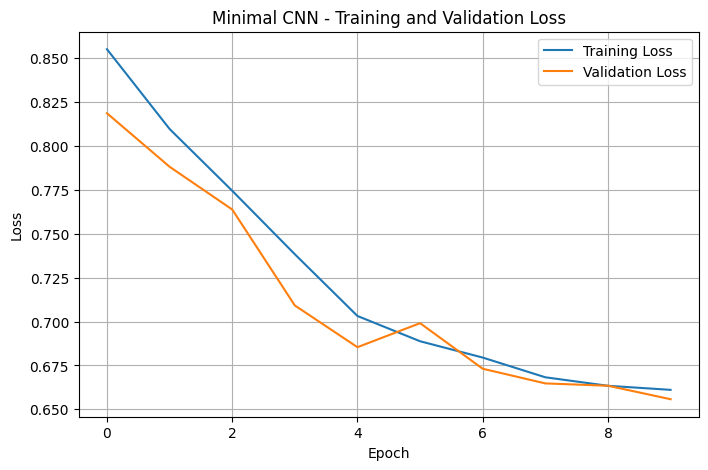

In [ ]:
# Evaluation
#7. PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Minimal CNN - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()





In [ ]:
# 8. VALIDATION LOSS


# During development, evaluate on validation data only.
evaluation_ds = val_ds

val_loss = minimal_cnn.evaluate(
    evaluation_ds,
    verbose=1
)

print(f"\nValidation Loss: {val_loss:.4f}")

201/201 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - loss: 0.6558

Validation Loss: 0.6558


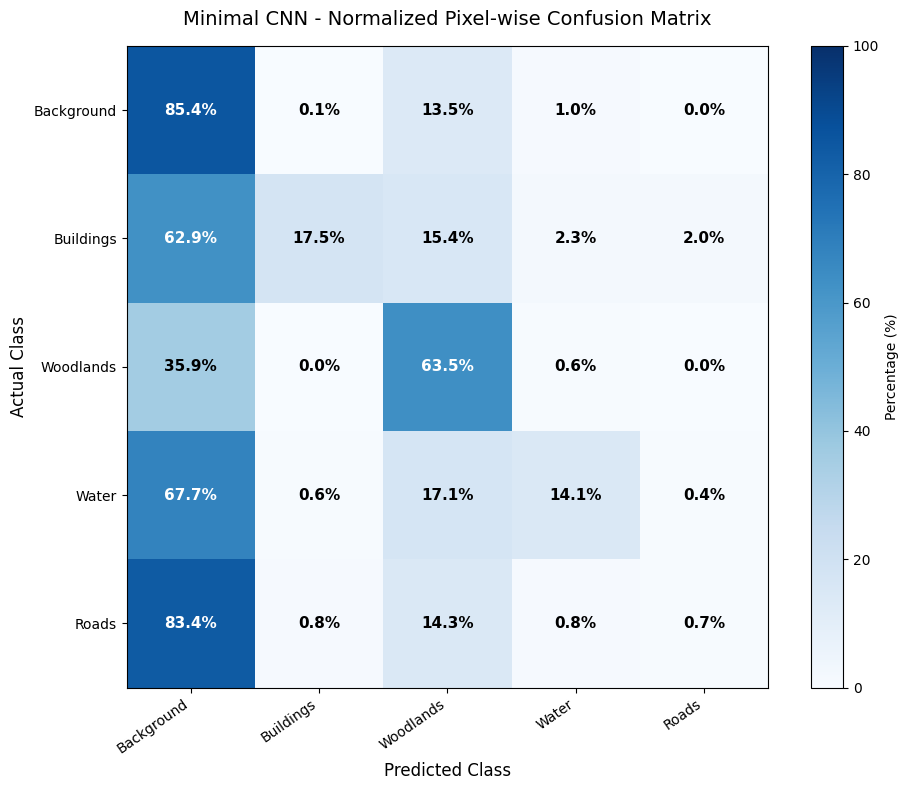

In [ ]:
confusion_matrix = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64
)

# Calculate confusion matrix
for images, masks in evaluation_ds:

    logits = minimal_cnn(
        images,
        training=False
    )

    predictions = tf.argmax(
        logits,
        axis=-1,
        output_type=tf.int32
    )

    batch_cm = tf.math.confusion_matrix(
        labels=tf.reshape(
            tf.cast(masks, tf.int32), [-1]
        ),

        predictions=tf.reshape(
            predictions, [-1]
        ),

        num_classes=NUM_CLASSES,
        dtype=tf.int64
    )

    confusion_matrix += batch_cm.numpy()


# Normalize each row to percentages
row_sums = confusion_matrix.sum(axis=1, keepdims=True)

normalized_cm = np.divide(
    confusion_matrix,
    row_sums,
    out=np.zeros_like(confusion_matrix, dtype=np.float64),
    where=row_sums != 0
) * 100


# Visualize confusion matrix
plt.figure(figsize=(10, 8))

plt.imshow(
    normalized_cm,
    interpolation="nearest",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title(
    "Minimal CNN - Normalized Pixel-wise Confusion Matrix",
    fontsize=14,
    pad=15
)

plt.colorbar(
    label="Percentage (%)"
)

tick_marks = np.arange(NUM_CLASSES)

plt.xticks(
    tick_marks,
    CLASS_NAMES,
    rotation=35,
    ha="right"
)

plt.yticks(
    tick_marks,
    CLASS_NAMES
)

plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)


# Add percentage annotations
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        value = normalized_cm[i, j]

        text_color = "white" if value > 50 else "black"

        plt.text(
            j,
            i,
            f"{value:.1f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=11,
            fontweight="bold"
        )


plt.tight_layout()
plt.show()

In [ ]:
# 10. CALCULATE SEGMENTATION METRICS


TP = np.diag(confusion_matrix).astype(np.float64)

actual_pixels = confusion_matrix.sum(axis=1)
predicted_pixels = confusion_matrix.sum(axis=0)

FP = predicted_pixels - TP
FN = actual_pixels - TP

# Intersection over Union
iou_denominator = TP + FP + FN

iou = np.divide(
    TP,
    iou_denominator,
    out=np.full(NUM_CLASSES, np.nan),
    where=iou_denominator != 0
)

# Dice Score
dice_denominator = (2 * TP) + FP + FN

dice = np.divide(
    2 * TP,
    dice_denominator,
    out=np.full(NUM_CLASSES, np.nan),
    where=dice_denominator != 0
)

# Precision
precision = np.divide(
    TP,
    predicted_pixels,
    out=np.full(NUM_CLASSES, np.nan),
    where=predicted_pixels != 0
)

# Recall
recall = np.divide(
    TP,
    actual_pixels,
    out=np.full(NUM_CLASSES, np.nan),
    where=actual_pixels != 0
)

# Macro metrics across all 5 classes
mean_iou = np.nanmean(iou)
mean_dice = np.nanmean(dice)

# Foreground metrics (excluding Background)
foreground_miou = np.nanmean(iou[1:])

# Pixel Accuracy: secondary metric
pixel_accuracy = TP.sum() / confusion_matrix.sum()




In [ ]:
# 11. DISPLAY PER-CLASS RESULTS


print("\n PER-CLASS EVALUATION")

for i, class_name in enumerate(CLASS_NAMES):

    print(f"\nClass: {class_name}")
    print(f"IoU:       {iou[i]:.4f}")
    print(f"Dice:      {dice[i]:.4f}")
    print(f"Precision: {precision[i]:.4f}")
    print(f"Recall:    {recall[i]:.4f}")


print("\n OVERALL RESULTS")

print(f"Mean IoU (5 classes): {mean_iou:.4f}")
print(f"Foreground mIoU:     {foreground_miou:.4f}")
print(f"Mean Dice:           {mean_dice:.4f}")
print(f"Pixel Accuracy:      {pixel_accuracy:.4f}")




 PER-CLASS EVALUATION

Class: Background
IoU:       0.6639
Dice:      0.7980
Precision: 0.7488
Recall:    0.8540

Class: Buildings
IoU:       0.1598
Dice:      0.2756
Precision: 0.6501
Recall:    0.1748

Class: Woodlands
IoU:       0.4891
Dice:      0.6569
Precision: 0.6801
Recall:    0.6353

Class: Water
IoU:       0.1235
Dice:      0.2198
Precision: 0.4959
Recall:    0.1412

Class: Roads
IoU:       0.0071
Dice:      0.0140
Precision: 0.1363
Recall:    0.0074

 OVERALL RESULTS
Mean IoU (5 classes): 0.2887
Foreground mIoU:     0.1949
Mean Dice:           0.3929
Pixel Accuracy:      0.7235


## **ERROR ANALYSIS - MINIMAL CNN BASELINE**

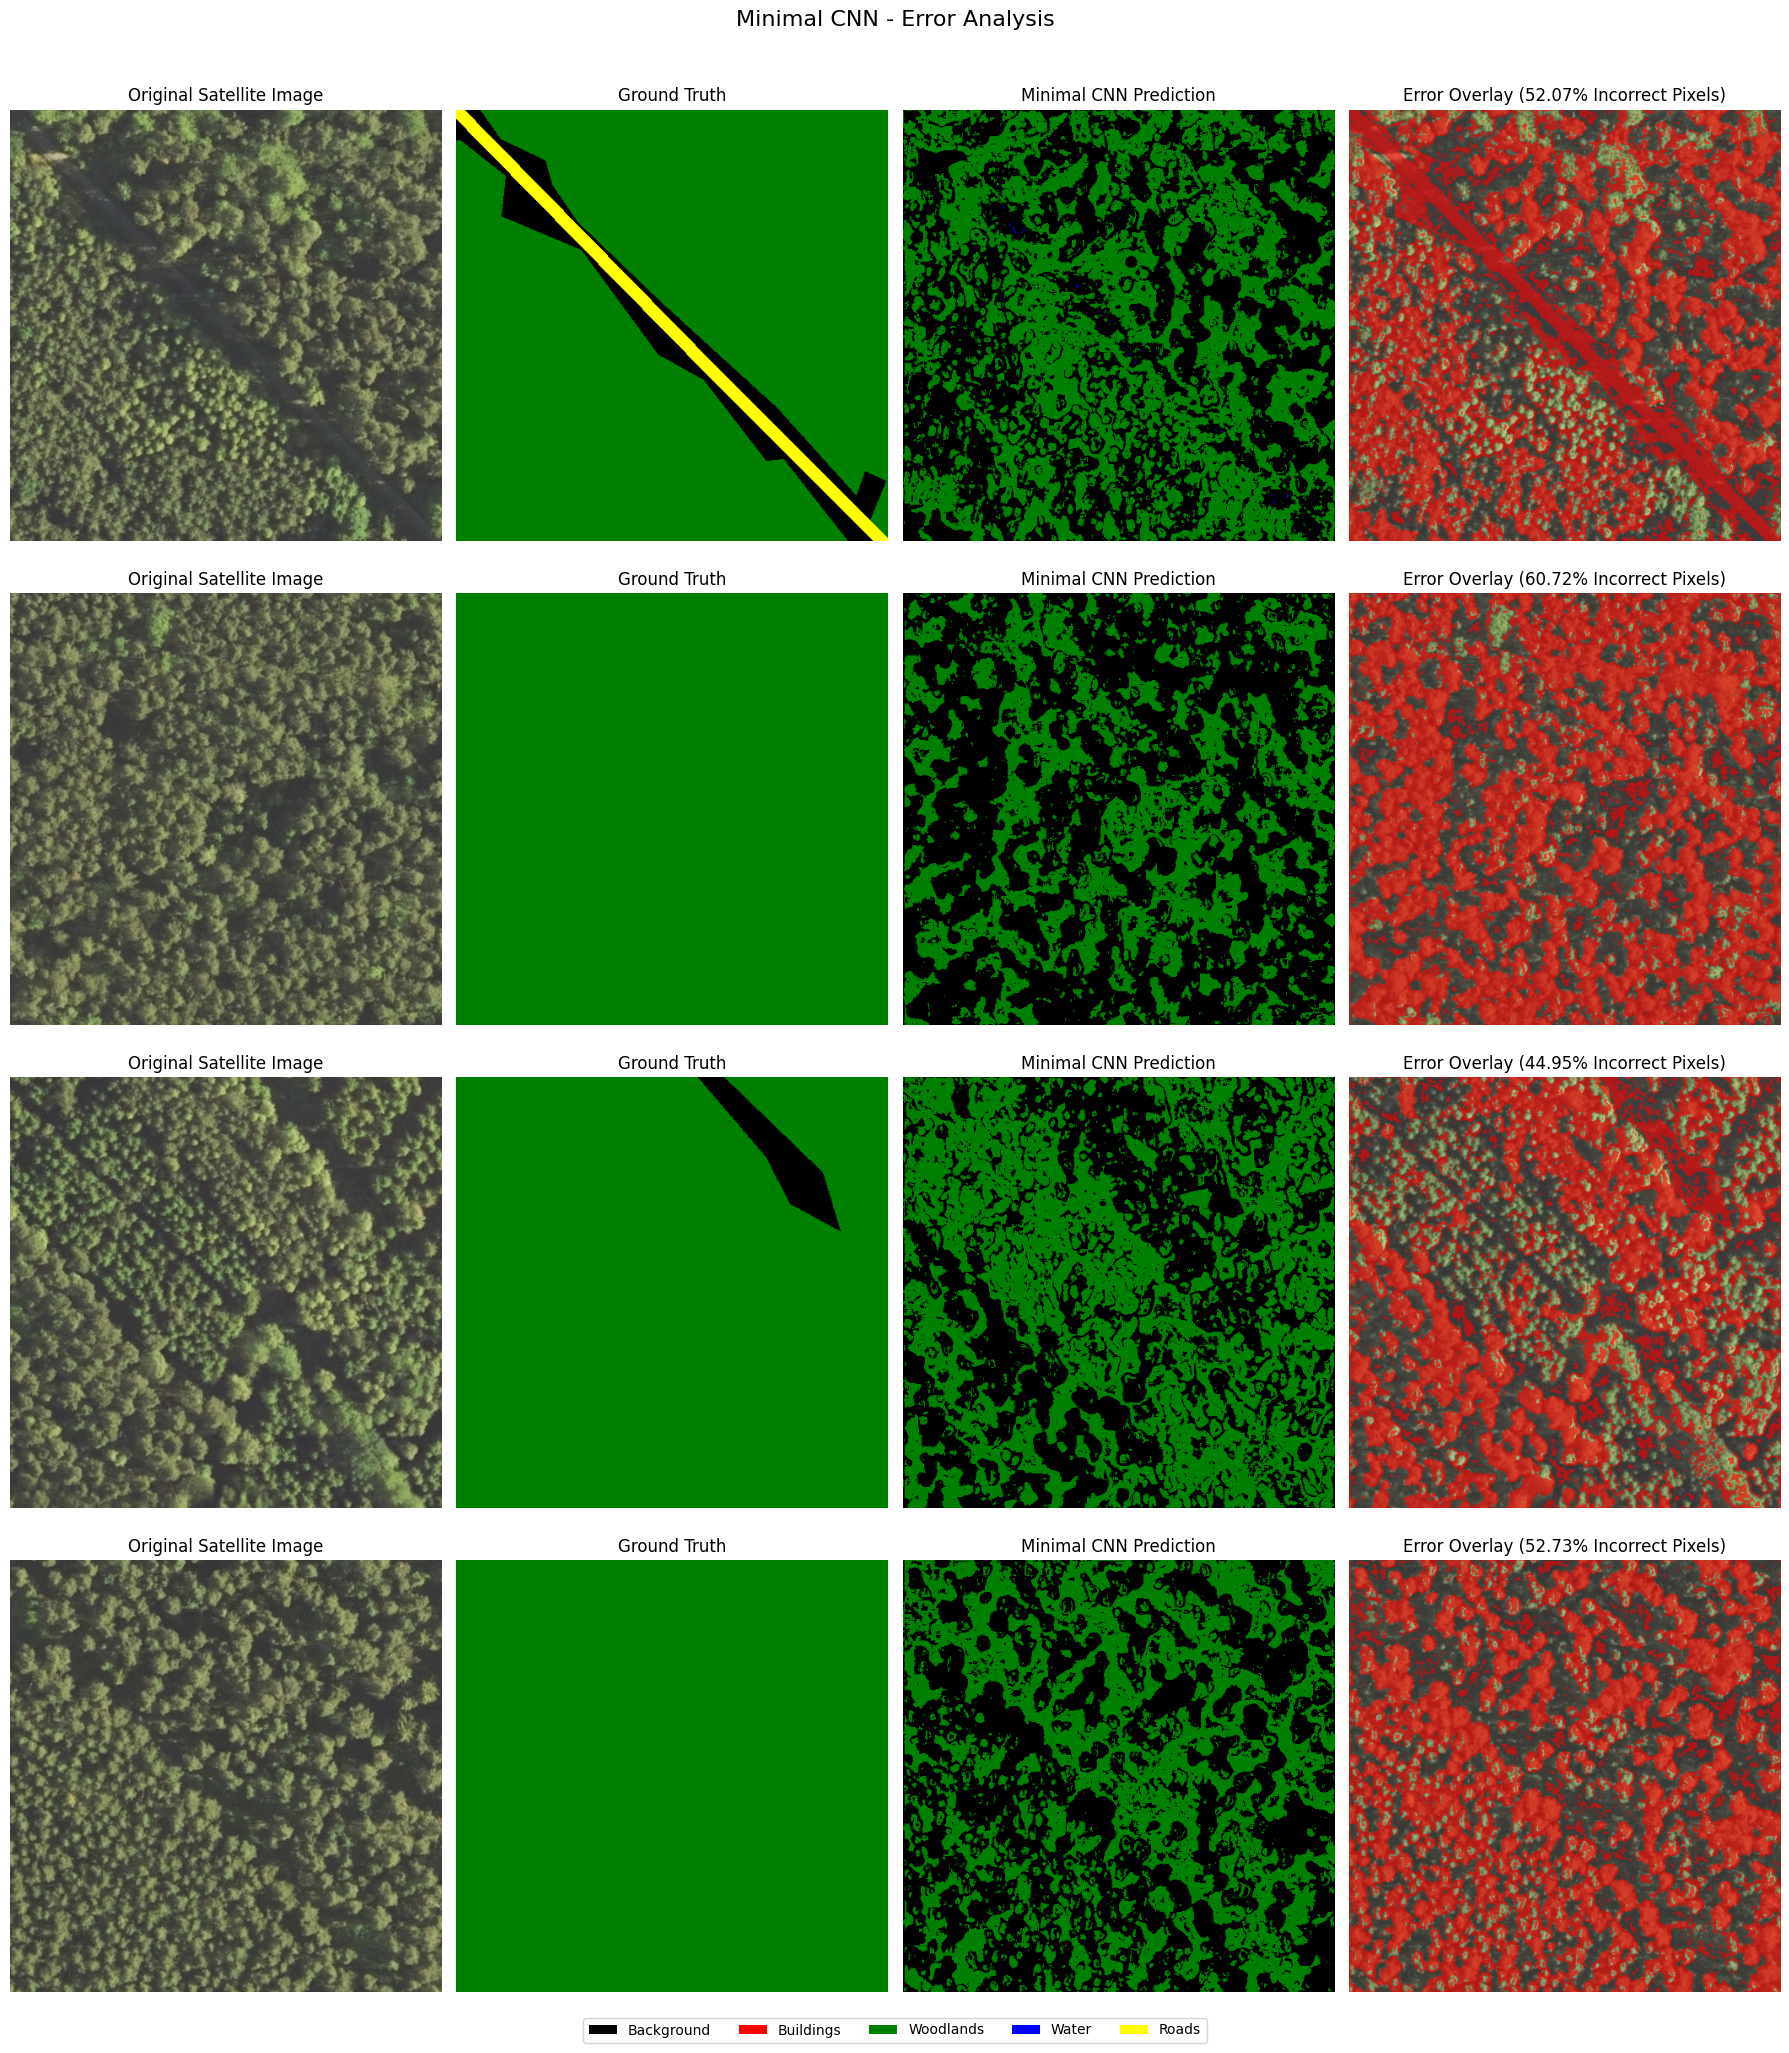


CLASS-WISE ERROR ANALYSIS

Class: Background
Total Pixels: 26,373
Incorrect Pixels: 16,259
Class Error Rate: 61.65%

Class: Buildings - Not present in selected images

Class: Woodlands
Total Pixels: 1,011,583
Incorrect Pixels: 524,826
Class Error Rate: 51.88%

Class: Water - Not present in selected images

Class: Roads
Total Pixels: 10,620
Incorrect Pixels: 10,620
Class Error Rate: 100.00%


In [ ]:
# 13. ERROR ANALYSIS - MINIMAL CNN BASELINE

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Class colors
CLASS_COLORS = [
    "black",       # Background
    "red",         # Buildings
    "green",       # Woodlands
    "blue",        # Water
    "yellow"       # Roads
]

segmentation_cmap = ListedColormap(CLASS_COLORS)

# ImageNet normalization values used in preprocessing
mean = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

std = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)


# Get one batch from validation dataset
for images_batch, masks_batch in evaluation_ds.take(1):

    # Model predictions
    logits = minimal_cnn(
        images_batch,
        training=False
    )

    predictions_batch = tf.argmax(
        logits,
        axis=-1,
        output_type=tf.int32
    )

    images_np = images_batch.numpy()
    masks_np = masks_batch.numpy()
    predictions_np = predictions_batch.numpy()

    break


# Number of examples to visualize
num_examples = min(4, len(images_np))

fig, axes = plt.subplots(
    num_examples,
    4,
    figsize=(18, 5 * num_examples),
    squeeze=False
)

for i in range(num_examples):

    # Denormalize image for visualization
    original_image = (
        images_np[i] * std + mean
    )

    original_image = np.clip(
        original_image,
        0,
        1
    )

    # Ground Truth and Prediction
    ground_truth = masks_np[i]
    predicted_mask = predictions_np[i]

    # Identify incorrect pixels
    wrong_pixels = (
        ground_truth != predicted_mask
    )

    # Create error overlay
    error_overlay = original_image.copy()

    red_color = np.array(
        [1.0, 0.0, 0.0]
    )

    error_overlay[wrong_pixels] = (
        0.4 * original_image[wrong_pixels]
        + 0.6 * red_color
    )

    # 1. Original Image
    axes[i, 0].imshow(original_image)
    axes[i, 0].set_title("Original Satellite Image")

    # 2. Ground Truth
    axes[i, 1].imshow(
        ground_truth,
        cmap=segmentation_cmap,
        vmin=0,
        vmax=NUM_CLASSES - 1
    )

    axes[i, 1].set_title("Ground Truth")

    # 3. Prediction
    axes[i, 2].imshow(
        predicted_mask,
        cmap=segmentation_cmap,
        vmin=0,
        vmax=NUM_CLASSES - 1
    )

    axes[i, 2].set_title("Minimal CNN Prediction")

    # 4. Error Overlay
    axes[i, 3].imshow(error_overlay)

    error_percentage = (
        np.mean(wrong_pixels) * 100
    )

    axes[i, 3].set_title(
        f"Error Overlay ({error_percentage:.2f}% Incorrect Pixels)"
    )

    for j in range(4):
        axes[i, j].axis("off")


# Class legend
legend_items = [
    Patch(
        facecolor=CLASS_COLORS[i],
        label=CLASS_NAMES[i]
    )
    for i in range(NUM_CLASSES)
]

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=NUM_CLASSES,
    bbox_to_anchor=(0.5, -0.01)
)

plt.suptitle(
    "Minimal CNN - Error Analysis",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()


# 14. CLASS-WISE ERROR ANALYSIS


print("\nCLASS-WISE ERROR ANALYSIS")

selected_ground_truth = masks_np[:num_examples]
selected_predictions = predictions_np[:num_examples]

for class_id, class_name in enumerate(CLASS_NAMES):

    true_class_pixels = (
        selected_ground_truth == class_id
    )

    incorrect_class_pixels = (
        true_class_pixels
        & (selected_predictions != selected_ground_truth)
    )

    total_pixels = np.sum(true_class_pixels)
    incorrect_pixels = np.sum(incorrect_class_pixels)

    if total_pixels > 0:

        class_error_rate = (
            incorrect_pixels / total_pixels
        ) * 100

        print(f"\nClass: {class_name}")
        print(f"Total Pixels: {total_pixels:,}")
        print(f"Incorrect Pixels: {incorrect_pixels:,}")
        print(f"Class Error Rate: {class_error_rate:.2f}%")

    else:
        print(f"\nClass: {class_name} - Not present in selected images")


## **COMPUTATIONAL COST**

In [ ]:
# 12. COMPUTATIONAL COST


# Number of trainable and non-trainable parameters
total_parameters = minimal_cnn.count_params()

print("\n COMPUTATIONAL COST")

print(f"Total Parameters: {total_parameters:,}")

# Saved model size
if os.path.exists(MODEL_PATH):

    model_size_mb = os.path.getsize(MODEL_PATH) / (1024 ** 2)

    print(f"Model Size: {model_size_mb:.2f} MB")


# Inference time on one image
for images, _ in evaluation_ds.take(1):
    single_image = images[:1]
    break

# Warm-up runs
for _ in range(3):

    _ = minimal_cnn(
        single_image,
        training=False
    ).numpy()

# Actual inference timing
inference_repeats = 20

inference_start = time.perf_counter()

for _ in range(inference_repeats):

    _ = minimal_cnn(
        single_image,
        training=False
    ).numpy()

inference_end = time.perf_counter()

inference_time_ms = (
    (inference_end - inference_start)
    / inference_repeats
) * 1000

print(f"Inference Time per Image: {inference_time_ms:.2f} ms")

print("\nHardware:")
print(tf.config.list_physical_devices("GPU"))

print("\nMinimal CNN Baseline Pipeline Completed")


 COMPUTATIONAL COST
Total Parameters: 5,253
Model Size: 0.09 MB
Inference Time per Image: 7.84 ms

Hardware:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Minimal CNN Baseline Pipeline Completed
